# Plot fixed inversion results

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.size": 18,          # base size
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})

import das_tools.hammer_inversion.plotting as plo
from das_tools.hammer_inversion import load_inversion_results
from das_tools.utils import proj_path

# Inputs and outputs live under outputs/tap_inv_batch/ in the project
# (das_tools.utils.proj_path; DAS_LFI_OUTPUT_DIR moves it).
OUT = proj_path.output_dir("tap_inv_batch")
FIG_MAIN = proj_path.figures_dir("main_text")
FIG_DIR1 = FIG_MAIN / "6_hammer_inv"

FIG_SUP = proj_path.figures_dir("supplementary")
FIG_DIR2 = FIG_SUP / "S5_hammer_inv_eventwise"


E: mean=5.44036e+09, std=9.85837e+07, 90% CI=[5.26278e+09, 5.60398e+09] (equal_tailed)
nu: mean=0.216407, std=0.0397426, 90% CI=[0.148396, 0.279326] (equal_tailed)
h_i: mean=0.97911, std=0.00416753, 90% CI=[0.970791, 0.987835] (equal_tailed)


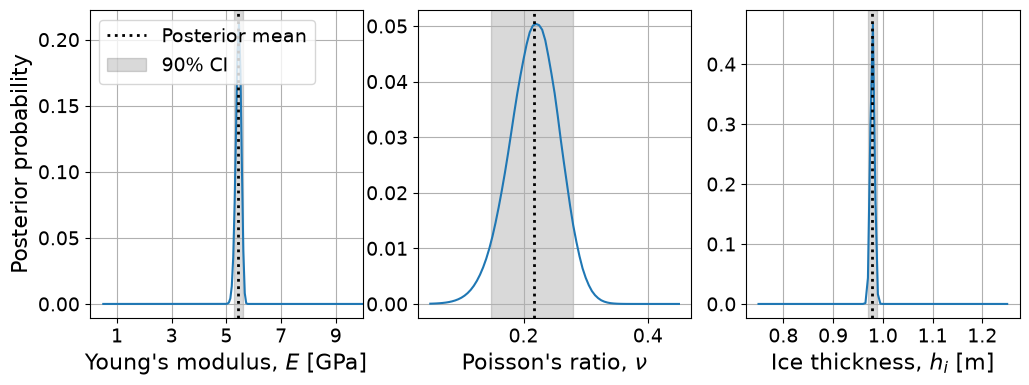

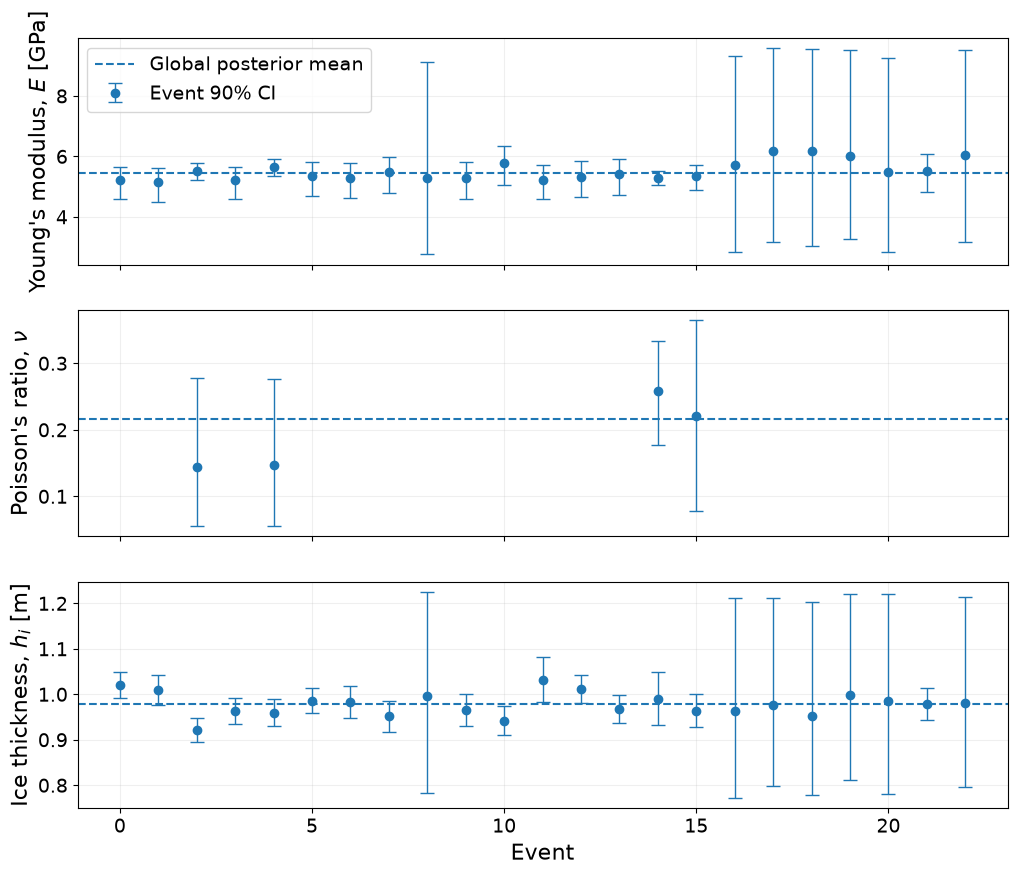

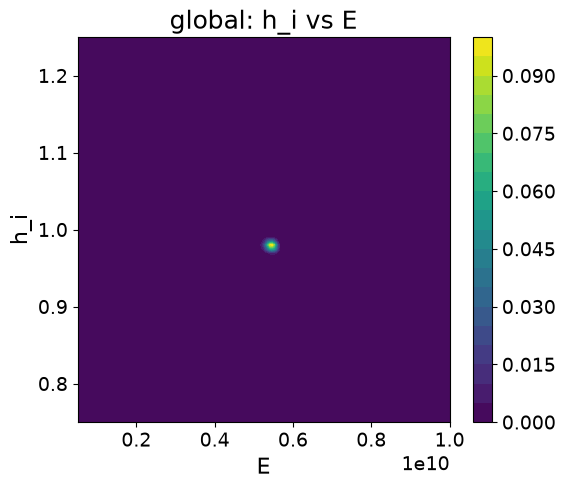

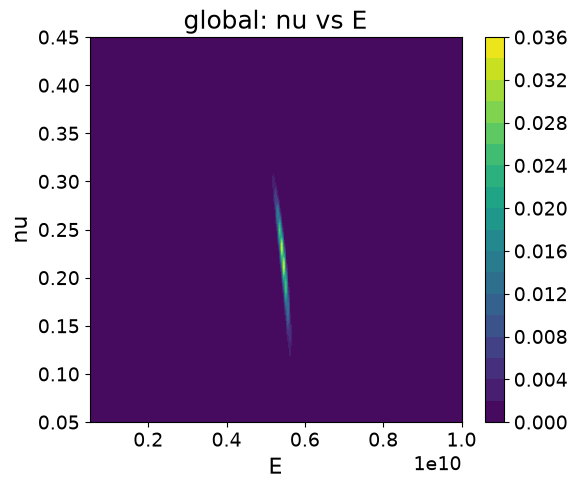

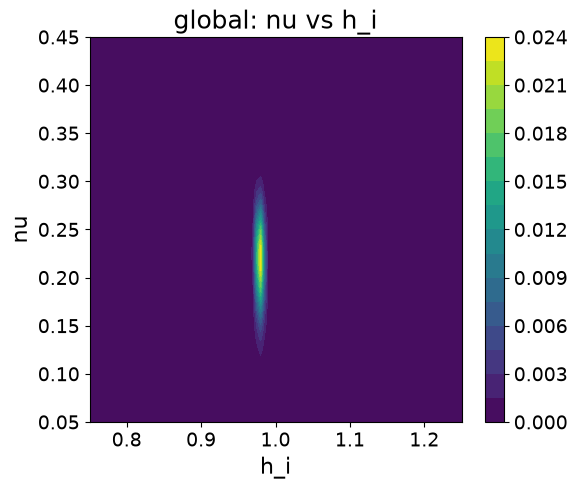

In [2]:
event_results, global_result = load_inversion_results(OUT / "inversion_results_fixed_0908_customSTD_noMod.npz")

CI_LEVEL = 0.90          # credible level for the intervals
CI_METHOD = "equal_tailed"  # or "hpd" for highest-posterior-density intervals

fig1, ax1 = plo.plot_marginals(global_result, ci_level=CI_LEVEL, ci_method=CI_METHOD)
fig1.savefig(FIG_DIR1 / "hammer_marginals.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.2,)

fig2,ax2 = plo.plot_event_estimates(event_results, global_result, ci_level=CI_LEVEL, ci_method=CI_METHOD,
                         param_events={"nu":[2,4,14,15]})
fig2.savefig(FIG_DIR2 / "hammer_eventwise_marginals.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.2,)
plo.plot_2d_marginal(global_result, "E", "h_i")
plo.plot_2d_marginal(global_result, "E", "nu")
plo.plot_2d_marginal(global_result, "h_i", "nu")
plt.show()